# Phase 2 - Exploratory Data Analysis

Data is read **from the MySQL database** `restaurant_intelligence` (loaded by `run_pipeline.py`). All figures and numbers below are computed when the notebook runs; nothing is typed in.

Statistical tests are non-parametric and show **association, not causation**.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src.db import get_engine, check_connection, read_sql
from src.eda import run_eda
pd.set_option('display.max_colwidth', 120)
engine = get_engine()
print('Connected to MySQL', check_connection(engine))

Connected to MySQL 8.4.9


## 1. Tables in MySQL

In [2]:
read_sql(engine, "SELECT 'countries' AS table_name, COUNT(*) AS row_count FROM countries "
                 "UNION ALL SELECT 'restaurants', COUNT(*) FROM restaurants "
                 "UNION ALL SELECT 'restaurant_cuisines', COUNT(*) FROM restaurant_cuisines")

,table_name,row_count
0,countries,15
1,restaurants,9551
2,restaurant_cuisines,19705


## 2. Run the EDA (statistics + figures)

In [3]:
eda = run_eda(engine)
kf = eda['key_figures']
pd.Series(kf, name='value').to_frame()

,value
n,9551
rated,7403
unrated,2148
india_share,90.587373
top4_cities,"[New Delhi, Gurgaon, Noida, Faridabad]"
top4_share,82.944194
india_cities,43
india_cities_le_25,39
rating_mean,3.440024
rating_median,3.4


## 3. Statistical tests

In [4]:
st = eda['statistics'][['question','test','groups','statistic','p_value','effect_measure','effect_size','significant_at_0_05']]
st

,question,test,groups,statistic,p_value,effect_measure,effect_size,significant_at_0_05
0,Is rating associated with number of votes? (rated restaurants),Spearman correlation,"n=7,403",0.682,0.000000e+00,rho,0.682,True
1,Does rating differ across price ranges?,Kruskal-Wallis H,"4 groups, n=7,403",1326.100,3.249781e-287,epsilon-squared,0.179,True
2,Is price range associated with rating?,Spearman correlation,"n=7,403",0.402,3.020560e-285,rho,0.402,True
3,India: does rating differ with online delivery?,Mann-Whitney U,"Delivery (n=2,327, median=3.40) vs No delivery (n=4,186, median=3.30)",5232985.000,5.883229e-07,rank-biserial r,0.074,True
4,India: does rating differ with table booking?,Mann-Whitney U,"Booking (n=1,064, median=3.60) vs No booking (n=5,449, median=3.30)",3730574.500,6.773395e-50,rank-biserial r,0.287,True
5,India: is cost for two (INR) associated with rating?,Spearman correlation,"n=6,504",0.332,1.693384e-167,rho,0.332,True
6,Is the number of cuisines offered associated with rating?,Spearman correlation,"n=7,394",0.118,3.508983e-24,rho,0.118,True
7,Is popularity class independent of price range?,Chi-square independence,"4x3 table, n=7,403, dof=6",1427.600,2.507819e-305,Cramer's V,0.311,True
8,Is popularity class independent of online delivery?,Chi-square independence,"2x3 table, n=7,403, dof=2",373.200,9.233347e-82,Cramer's V,0.225,True
9,Is popularity class independent of table booking?,Chi-square independence,"2x3 table, n=7,403, dof=2",513.000,3.985543e-112,Cramer's V,0.263,True


## 4. Figures

**fig01_restaurants_by_country**

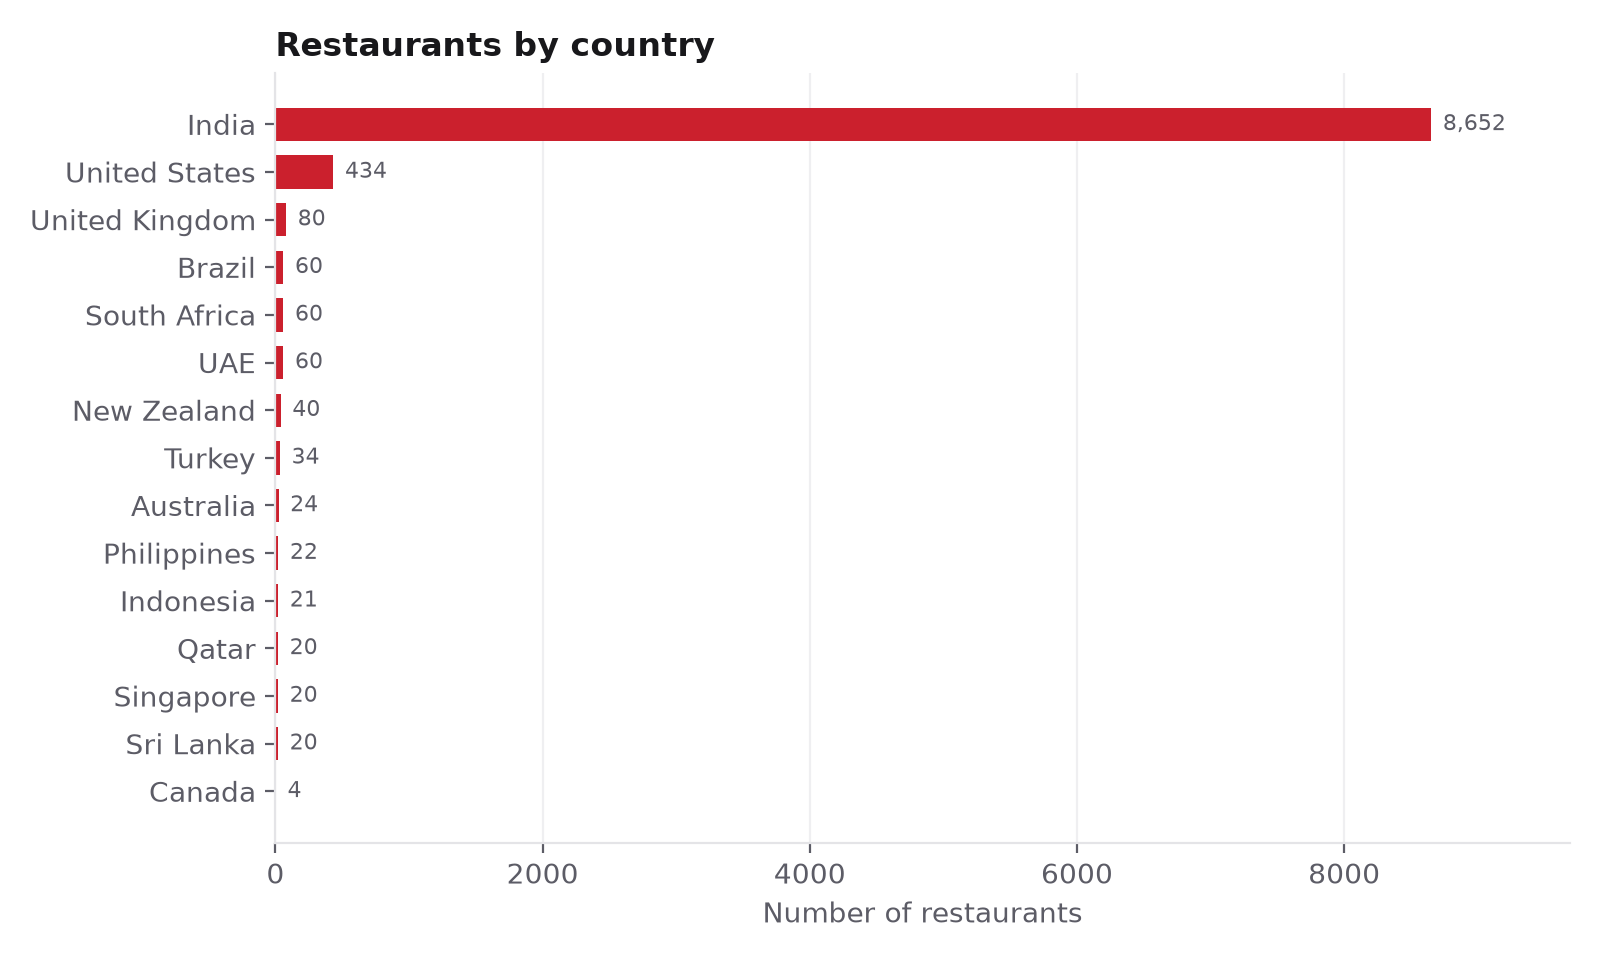

**fig02_top_cities**

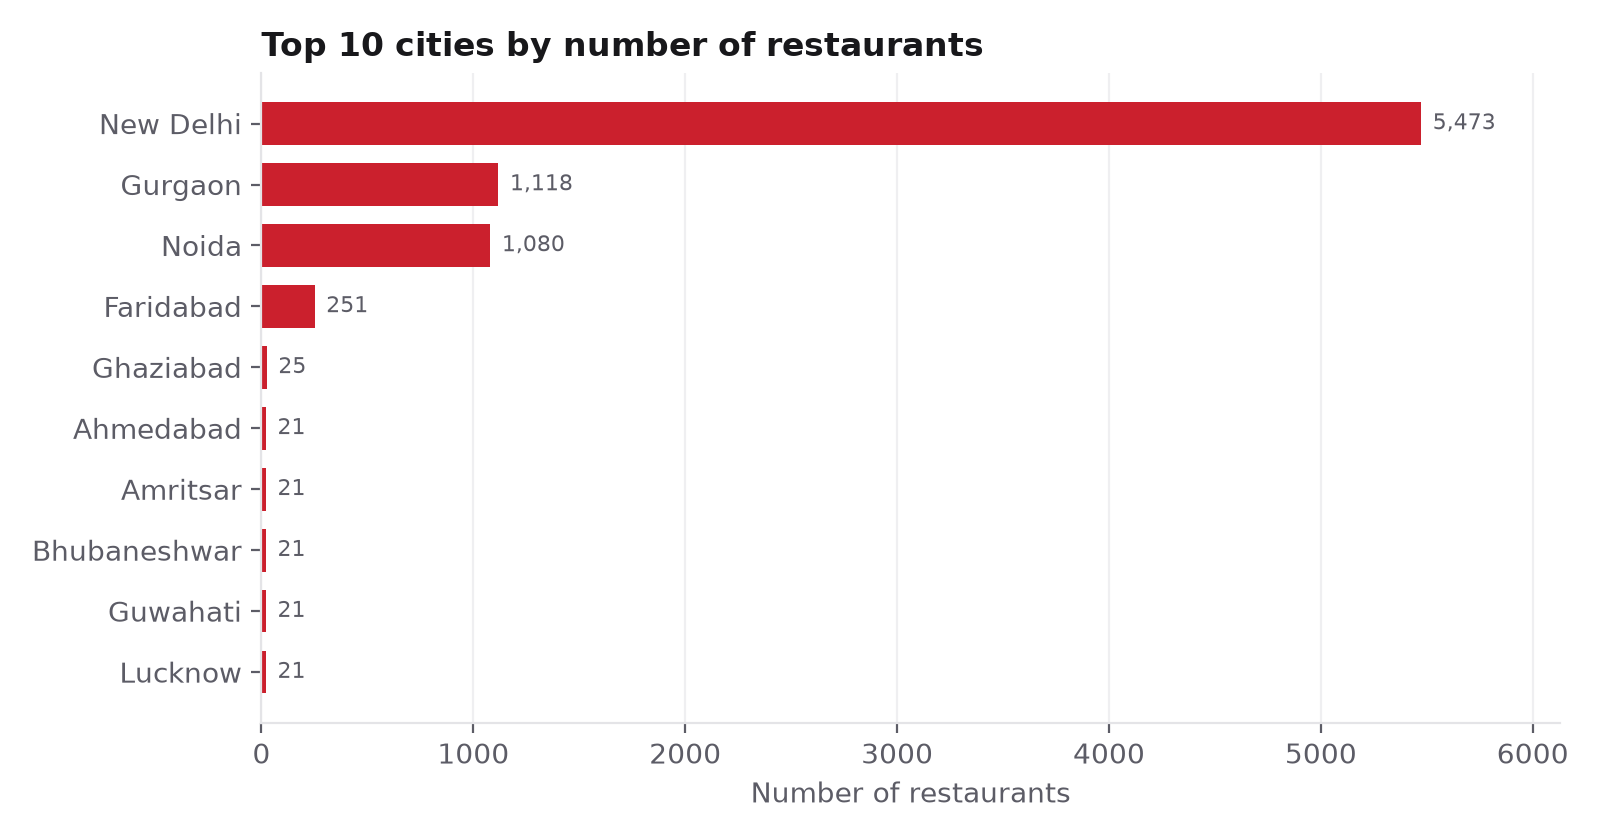

**fig03_rating_distribution**

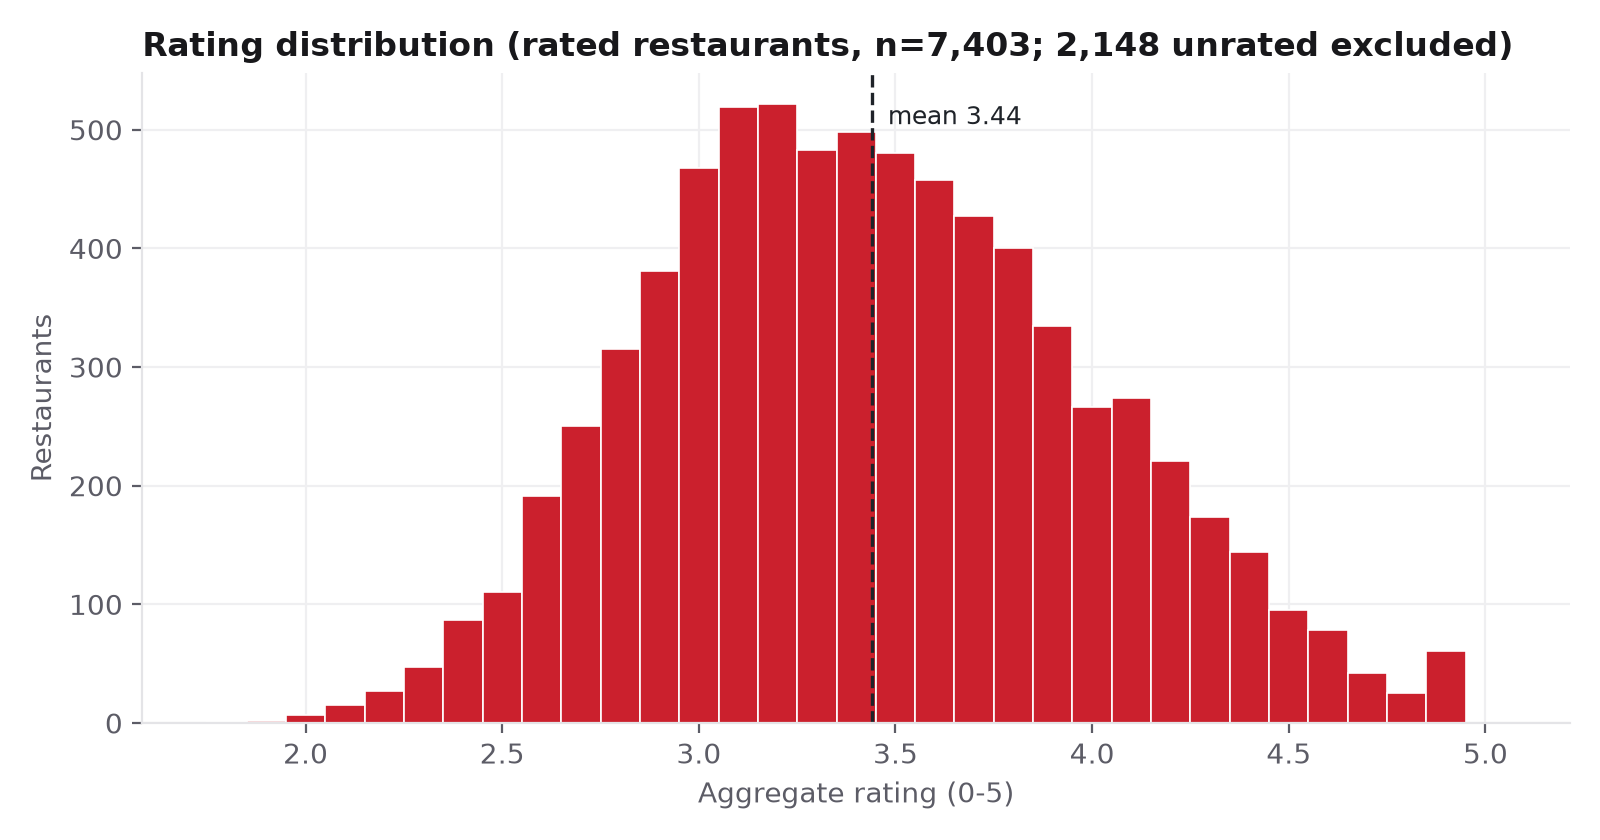

**fig04_top_cuisines**

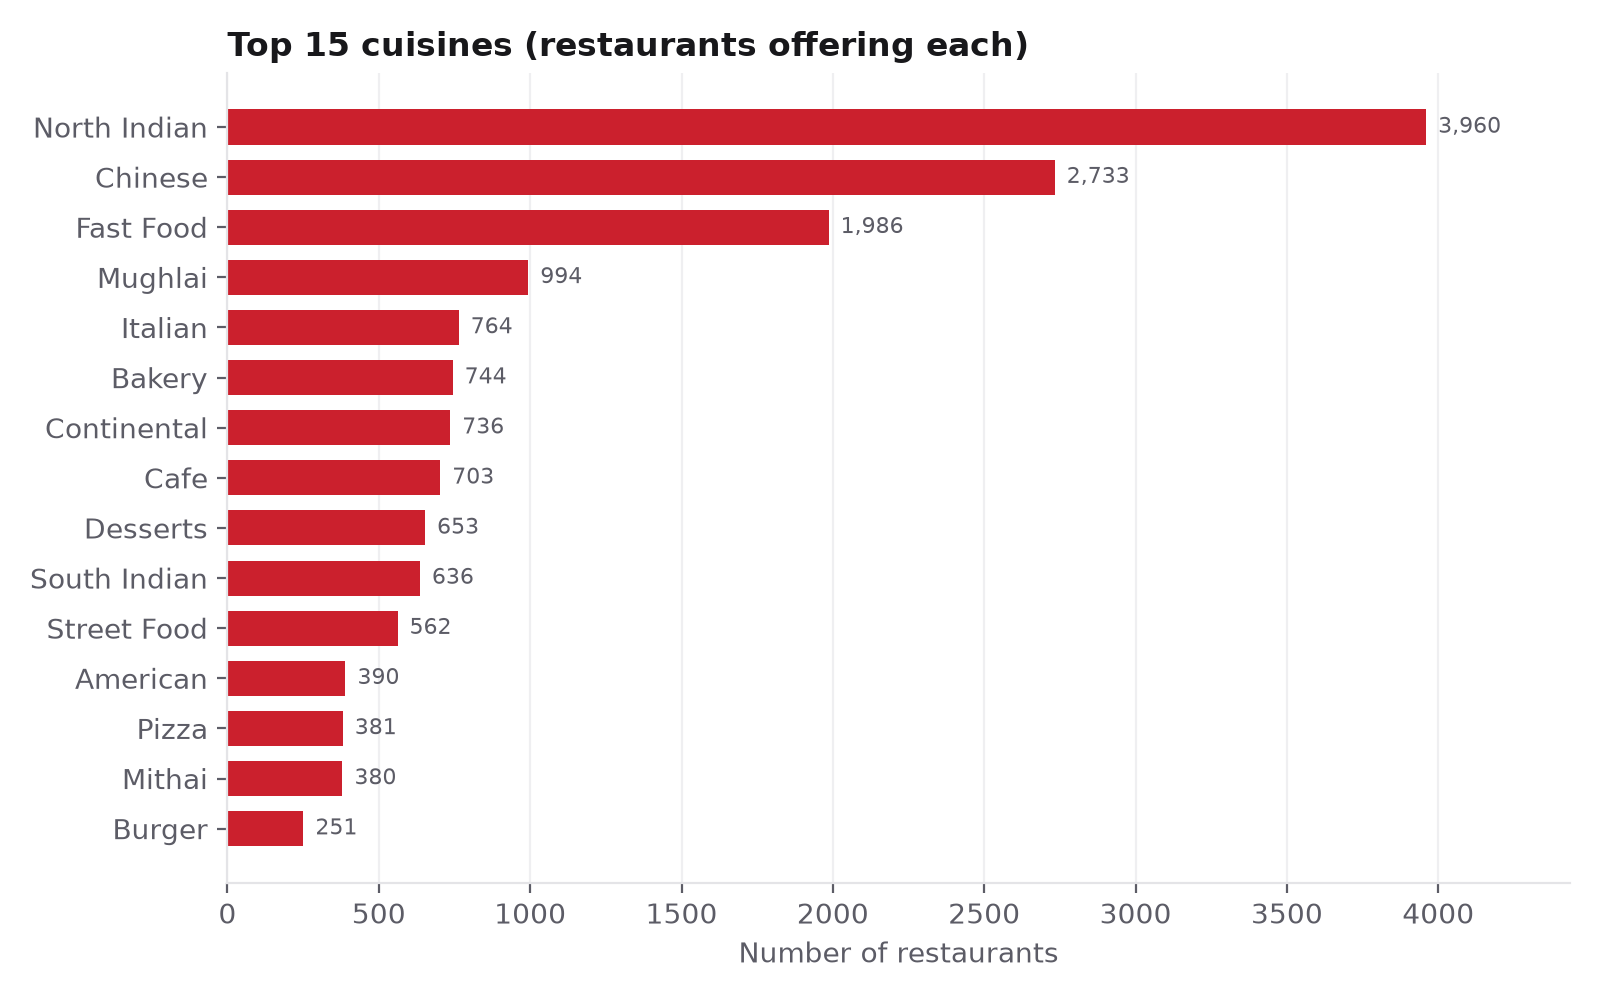

**fig05_price_range_mix**

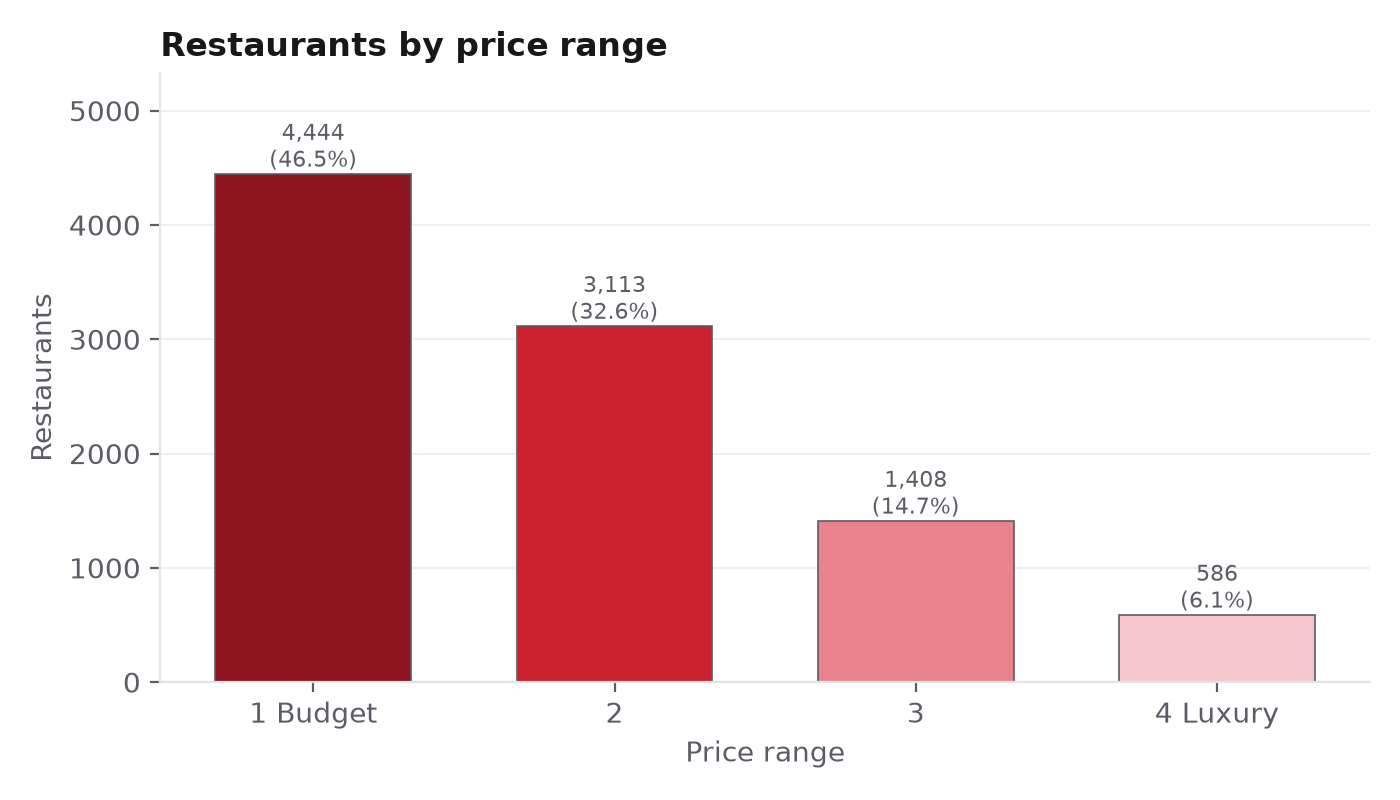

**fig06_rating_by_price_range**

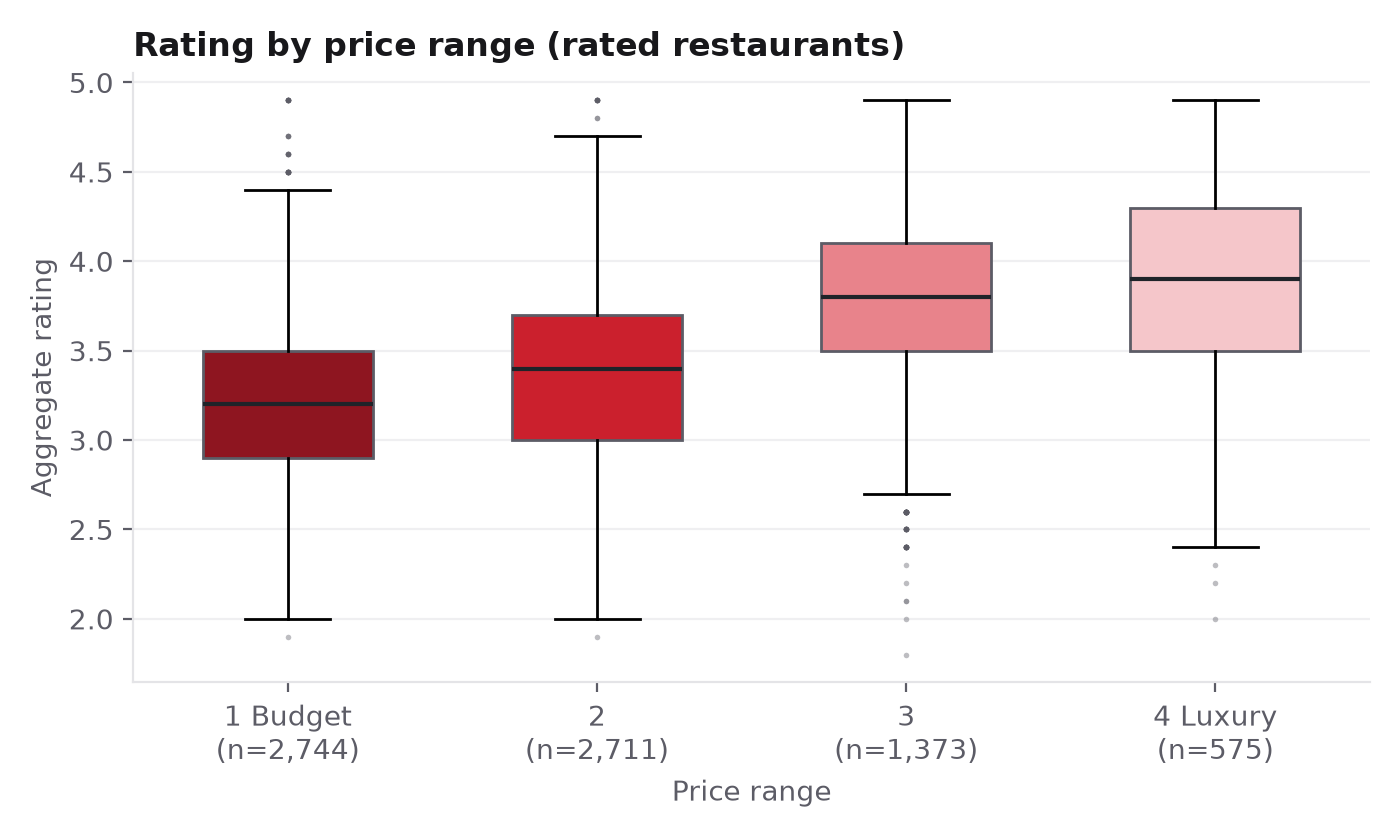

**fig07_votes_vs_rating**

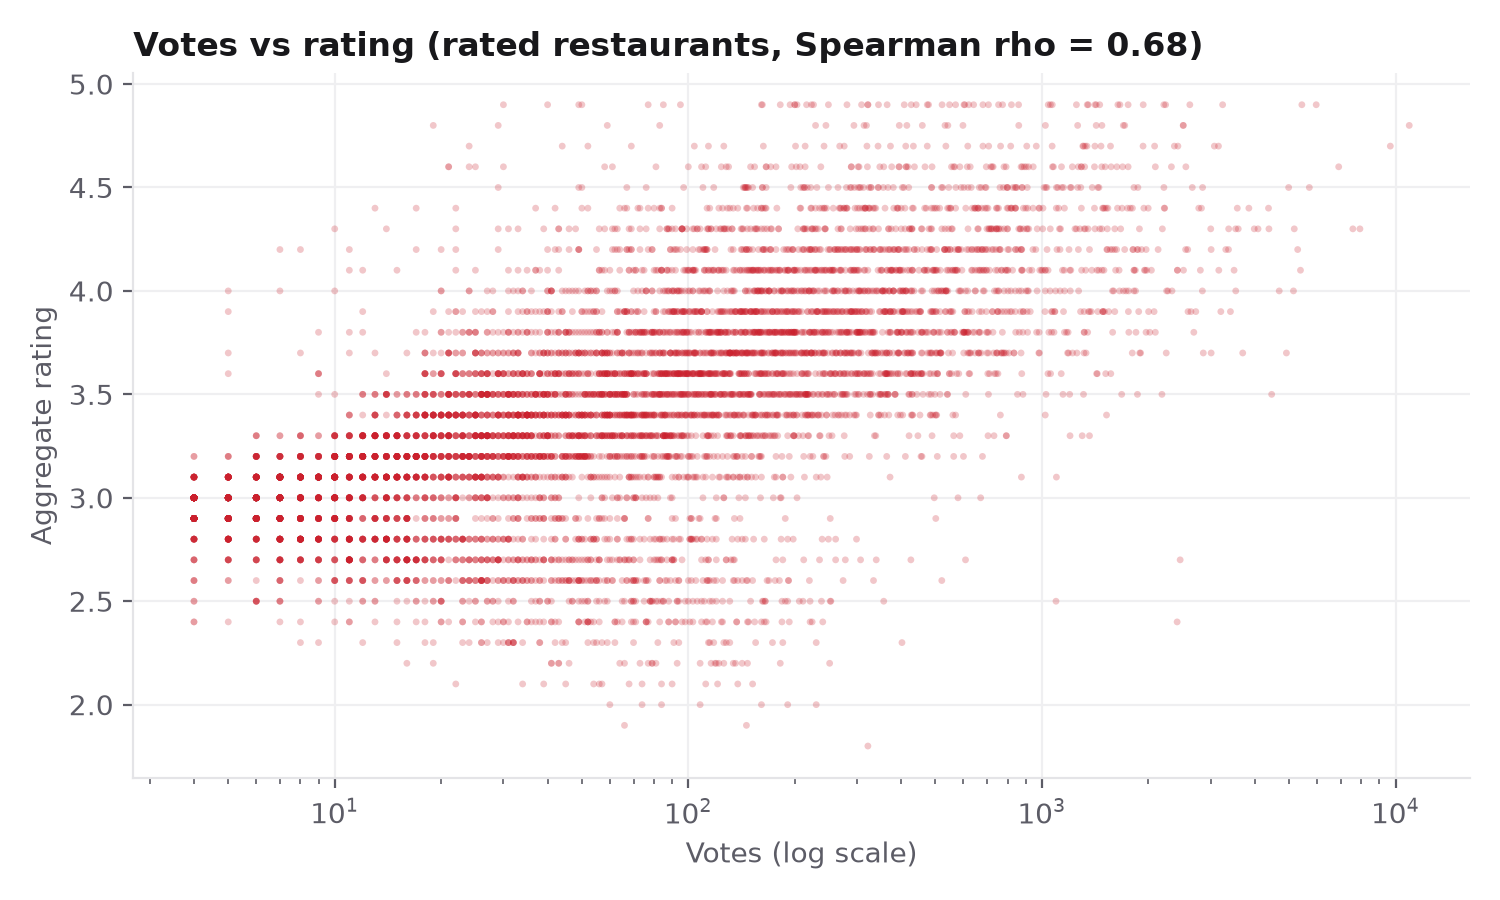

**fig08_services_vs_rating_india**

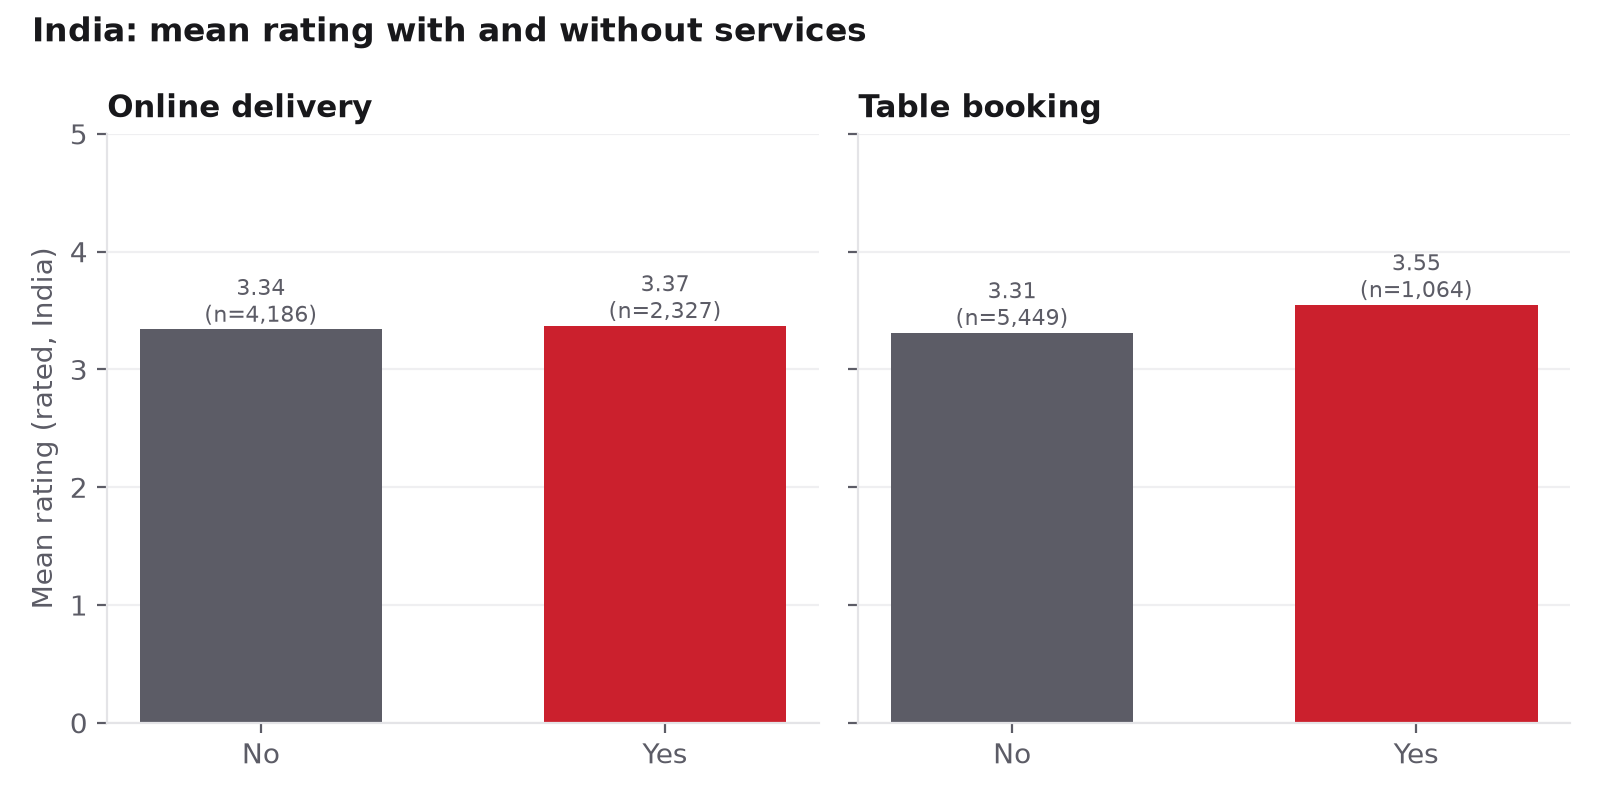

**fig09_popularity_by_price_range**

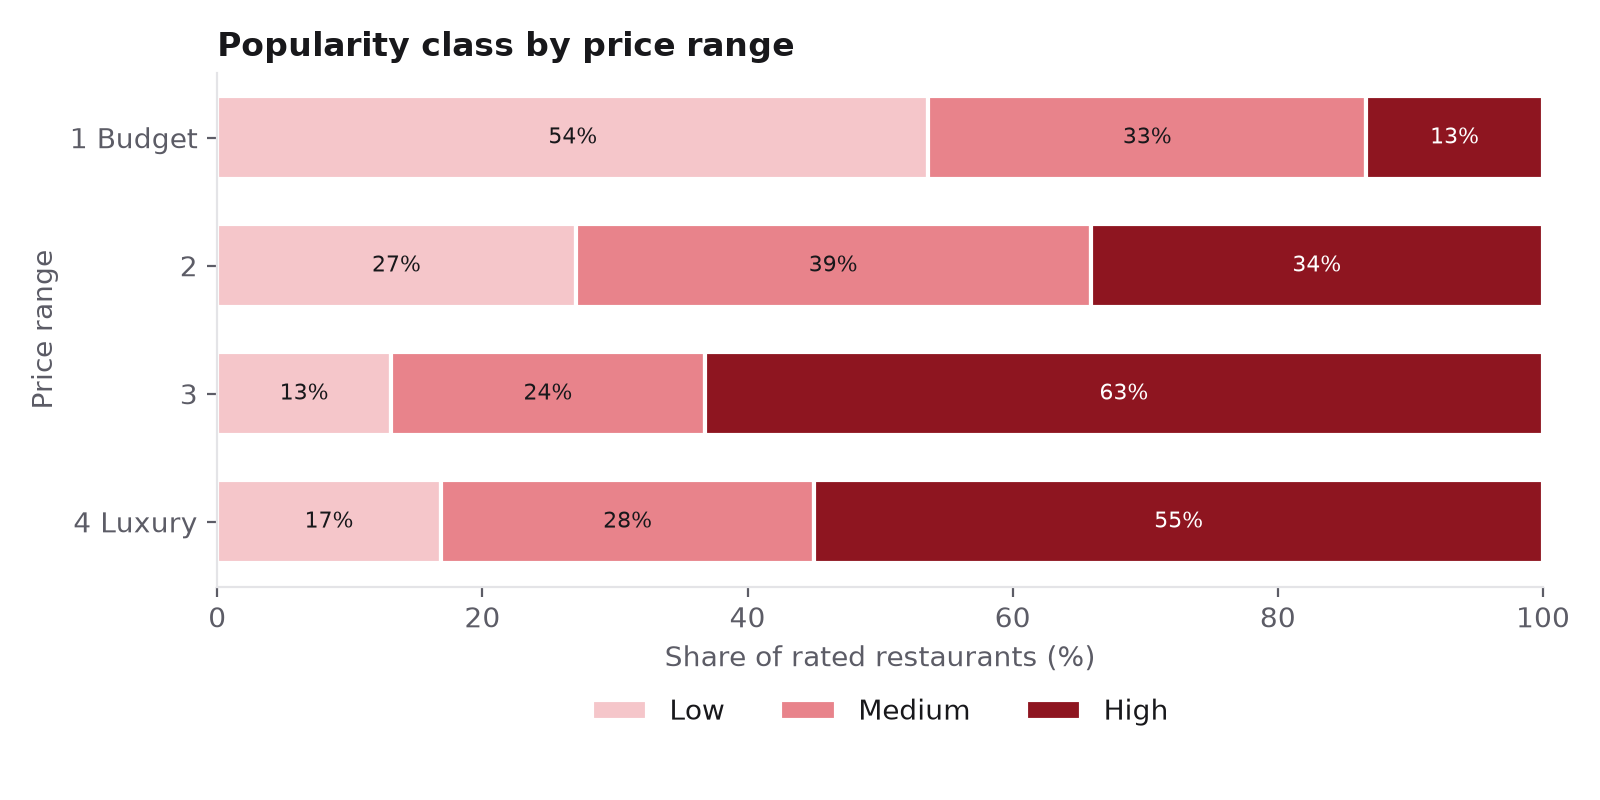

**fig10_high_popularity_by_services**

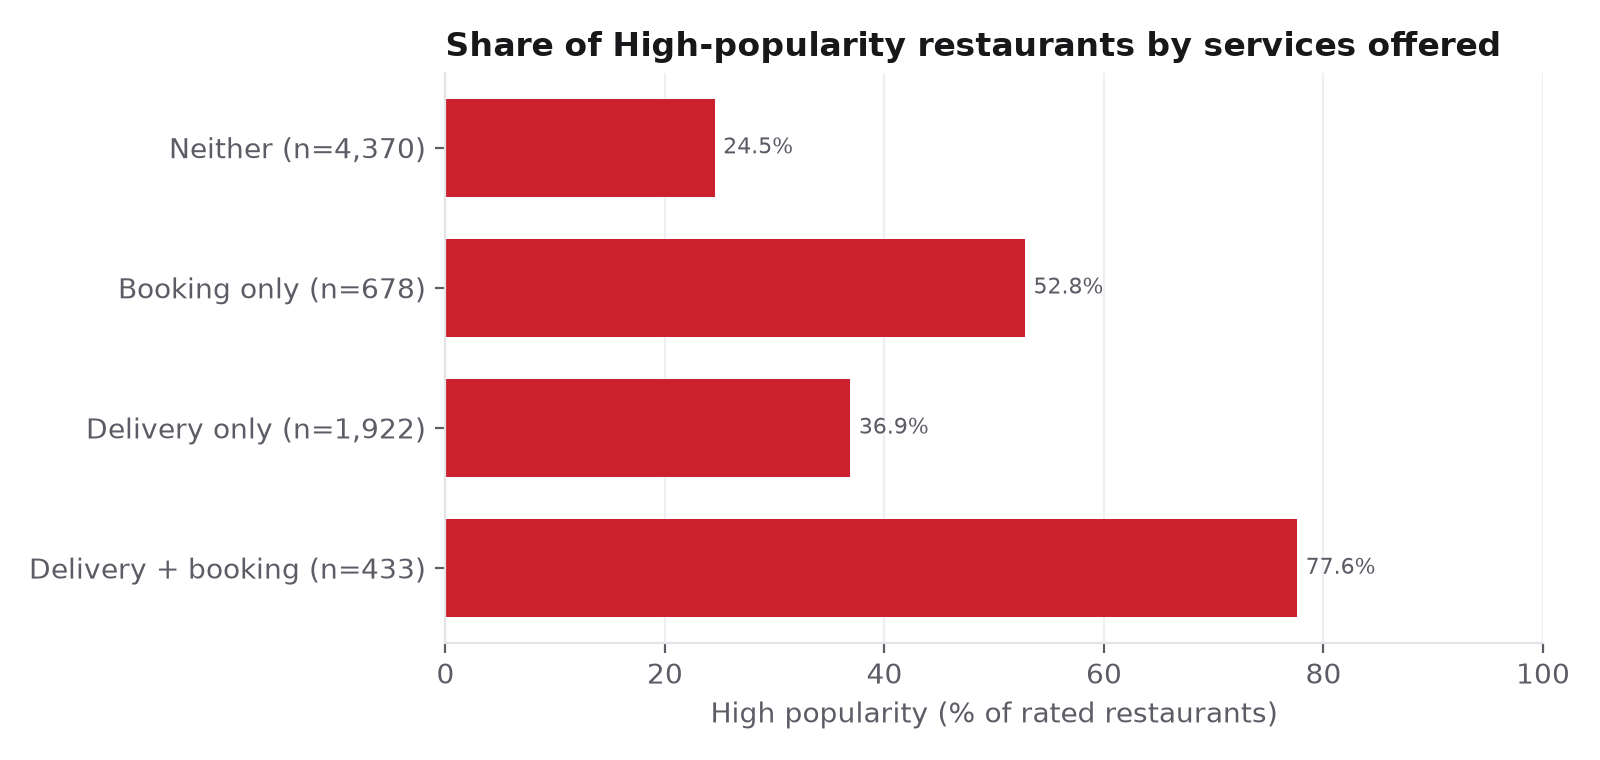

**fig11_locality_competition**

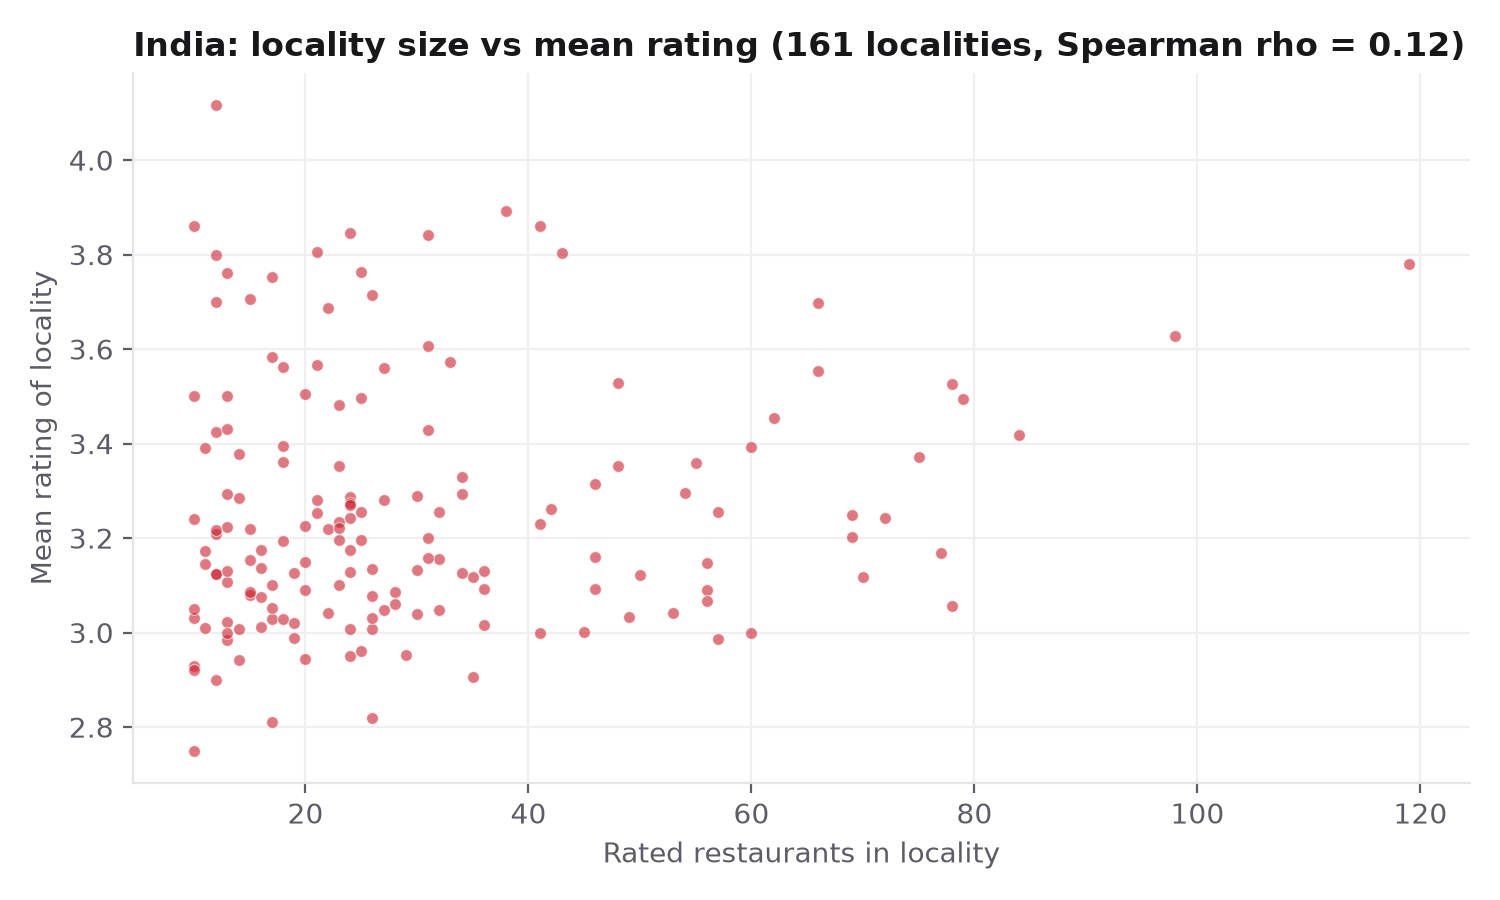

**fig12_rating_by_cuisine**

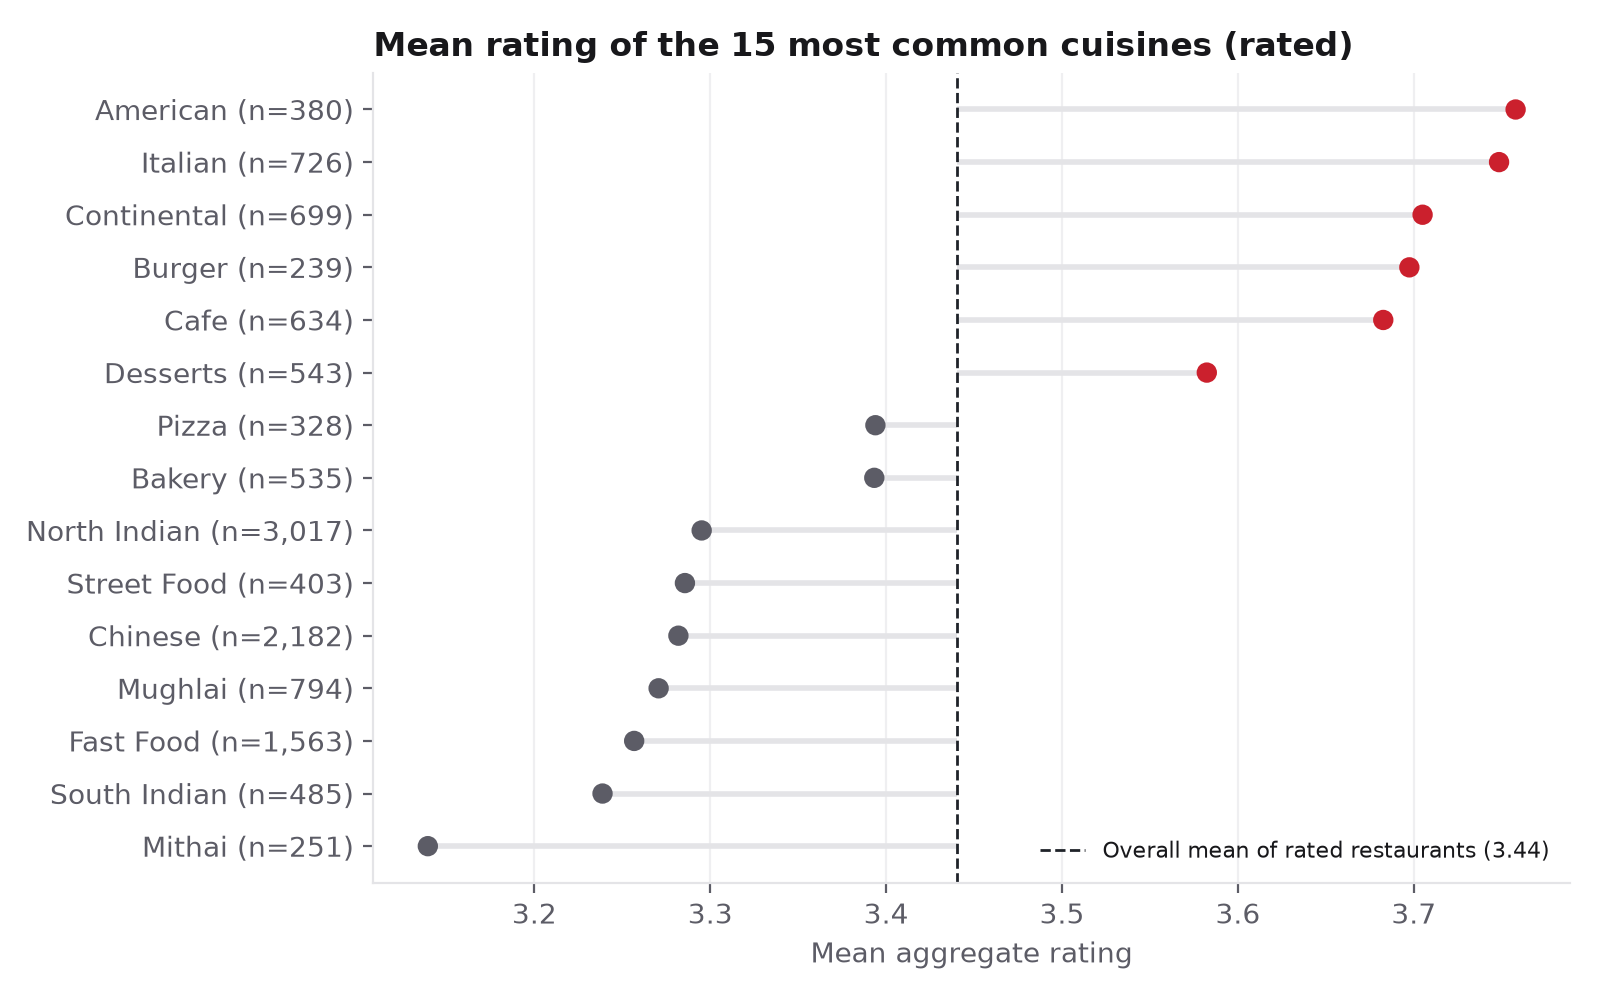

In [5]:
for p in eda['figures']:
    display(Markdown(f'**{p.stem}**'))
    display(Image(filename=str(p), width=720))

## 5. Example: a view queried directly from MySQL

In [6]:
read_sql(engine, 'SELECT * FROM v_price_summary ORDER BY price_range')

,price_range,restaurants,rated_restaurants,avg_rating,avg_votes,online_delivery_pct,table_booking_pct
0,1,4444,2744.0,3.24,44.6,15.8,0.0
1,2,3113,2711.0,3.38,147.6,41.3,7.7
2,3,1408,1373.0,3.78,443.9,29.2,45.7
3,4,586,575.0,3.89,368.6,9.0,46.8
